In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pickle

import pandas as pd
import numpy as np
from scipy.signal import resample

from utils.plots import *
from utils.infer import run_bayesian_pd


In [3]:
param_dir = Path('../../prior_params')
inpath = Path('rarker.csv')
outpath = Path('rarker_bpd.pkl')

prior = dict(
    alpha_hr  = np.load(param_dir / "alpha_hr.npy"),
    lambd_hr  = np.load(param_dir / "lambd_hr.npy"),
    alpha_zpp = np.load(param_dir / "alpha_zpp.npy"),
    mu_w      = np.load(param_dir / "mu_w.npy"),
    L_w   = np.load(param_dir / "L_w.npy"),
    f_h       = np.load(param_dir / "f_h.npy"),
    g       = np.load(param_dir / "g.npy"),
)


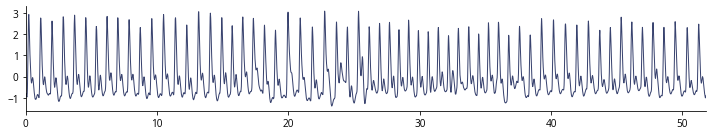

In [4]:
data_path = Path(inpath)
df = pd.read_csv(data_path)
t, y = df.t.values.copy(), df.y.values.copy()
fs = (len(t)-1)/(t[-1]-t[0])
t -= t[0]
y -= y.mean()
y /= y.std()

y, t = resample(y, y.size//5, t)
y, t = resample(y, y.size*5, t)

plt.figure(figsize=(10,2))
plt.plot(t, y)
plt.show()


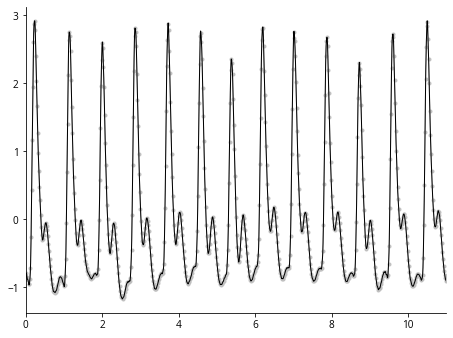

In [5]:
duration = 11
fs_obs = 64

# trim
t -= t[0]
region = (t <= duration)
t = t[region]
y = y[region]

# resample
N_ds = int(np.round(y.size*fs_obs/fs))
y_obs, t_obs = resample(y, N_ds, t)

plt.plot(t_obs, y_obs, '.-', c=cp[-1])
plt.plot(t, y, '-', c='k')
plt.show()


In [6]:
soln = run_bayesian_pd(t_obs, y_obs, prior, seed=0)


In [7]:
with open(outpath, 'wb') as f:
    pickle.dump(soln, f)
